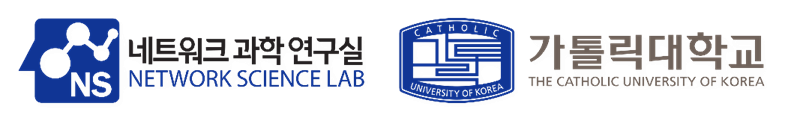

# Week 10: Graph Transformers

<a target="_blank" href="https://colab.research.google.com/github/NSLab-CUK/Graph-Neural-Networks-Fall-2026/blob/main/W10/SampleCode_10.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

### The idea in two sentences

* In a GNN such as **GAT**, each node uses attention over its **direct neighbors** only. Information from a node 6 hops away needs 6 layers to arrive.
* In a **Graph Transformer**, each node uses attention over **every other node** in a single layer.

There is one catch: if every node talks to every node, the model forgets **which nodes are connected**. We fix this by giving each node a **position tag** (a *positional encoding*).

In this notebook we work with molecules (**ZINC** dataset) and:

1. compute attention by hand on one molecule,
2. see why attention alone ignores the graph, and fix it with position tags,
3. train a **Graph Transformer** and compare it with **GAT**,
4. look at what the trained attention focuses on.

<!-- Helper cells (imports, plotting) are collapsed; click on them to see the code. -->

## Table of contents

- [1. Setup](#1-setup)
- [2. The ZINC dataset](#2-the-zinc-dataset)
- [3. Attention: every atom talks to every atom](#3-attention-every-atom-talks-to-every-atom)
- [4. Positional encodings: where is each atom?](#4-positional-encodings-where-is-each-atom)
- [5. GAT vs. Graph Transformer](#5-gat-vs-graph-transformer)
- [6. Results](#6-results)
- [7. What does attention look at?](#7-what-does-attention-look-at)
- [8. Takeaways](#8-takeaways)

## 1. Setup

In [1]:
# @title Install dependencies (Colab)
INSTALL_DEPENDENCIES = False

if INSTALL_DEPENDENCIES:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch-geometric"])

In [2]:
# @title Imports and colors
import contextlib
import io
import tempfile
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # Optional PyG extension notices.

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch_geometric.transforms as T
from torch_geometric.datasets import ZINC
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATConv, global_add_pool
from torch_geometric.utils import to_dense_adj, to_dense_batch, to_networkx

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
ROOT = f"{tempfile.gettempdir()}/pyg_datasets"  # PyG downloads datasets here on first use.

# One color per role, reused in every figure.
MODEL_COLORS = {"GAT": "#2a78d6", "Graph Transformer": "#1baf7a"}
CARBON_COLORS = {"A": "#4a3aa7", "B": "#eda100", "C": "#e87ba4"}
ATOM_COLORS = {"C": "#7a7a7a", "O": "#e34948", "N": "#2a78d6", "S": "#eda100", "other": "#1baf7a"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
print(f"torch {torch.__version__} | device: {DEVICE}")

torch 2.11.0+cu128 | device: cuda


## 2. The ZINC dataset

**ZINC** is the most common benchmark for Graph Transformers. We use its small version with 12,000 molecules:

* **Nodes** = atoms (28 types), **edges** = bonds (single, double or triple).
* **Goal**: predict one number per molecule, its *solubility score* (how well it dissolves).
* **Error measure**: mean absolute error (**MAE**). Lower is better.

When loading, we also compute a **position tag** for every atom (called `pe`). Section 4 explains it.

In [3]:
PE_DIM = 16                                            # length of each atom's position tag
add_pe = T.AddRandomWalkPE(walk_length=PE_DIM, attr_name="pe")

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):  # hide download log
    train_ds, val_ds, test_ds = (ZINC(f"{ROOT}/ZINC", subset=True, split=s, pre_transform=add_pe)
                                 for s in ("train", "val", "test"))

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=256)
test_loader = DataLoader(test_ds, batch_size=256)

ATOMS = ["C", "O", "N", "F", "C", "S", "Cl", "O", "N", "Br", "N", "N", "N", "N",
         "S", "I", "P", "O", "N", "O", "S", "P", "P", "C", "P", "S", "C", "P"]  # element of each atom type

mol = test_ds[7]                                       # one example molecule
print(f"train {len(train_ds)} / val {len(val_ds)} / test {len(test_ds)} molecules")
print(f"on average {train_ds.x.size(0) / len(train_ds):.0f} atoms per molecule")
print(f"example molecule: {mol.num_nodes} atoms, {mol.num_edges // 2} bonds, score {mol.y.item():.2f}")

train 10000 / val 1000 / test 1000 molecules
on average 23 atoms per molecule
example molecule: 22 atoms, 24 bonds, score -1.82


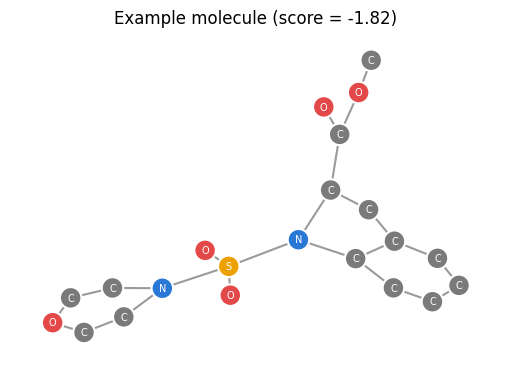

In [4]:
# @title Helper: draw a molecule
def mol_layout(m):
    return nx.spring_layout(to_networkx(m, to_undirected=True), seed=SEED, iterations=200)

def draw_mol(ax, m, pos, node_color=None, cmap=None, labels=True, highlight=None):
    G = to_networkx(m, to_undirected=True)
    elems = [ATOMS[t] for t in m.x.view(-1).tolist()]
    if node_color is None:
        node_color = [ATOM_COLORS.get(e, ATOM_COLORS["other"]) for e in elems]
    nx.draw_networkx_edges(G, pos, ax=ax, width=1.5, edge_color="#9a9a9a")
    nodes = nx.draw_networkx_nodes(G, pos, ax=ax, node_size=240, node_color=node_color, cmap=cmap,
                                   edgecolors="white", linewidths=1.5)
    if highlight is not None:
        nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=[highlight], node_size=380, node_color="none",
                               edgecolors="black", linewidths=2)
    if labels:
        nx.draw_networkx_labels(G, pos, ax=ax, labels=dict(enumerate(elems)), font_size=7, font_color="white")
    ax.set_axis_off()
    return nodes

pos = mol_layout(mol)
fig, ax = plt.subplots(figsize=(5, 3.6), constrained_layout=True)
draw_mol(ax, mol, pos)
ax.set_title(f"Example molecule (score = {mol.y.item():.2f})")
plt.show()

## 3. Attention: every atom talks to every atom

Attention works like a search. Every atom $i$ makes three vectors from its features:

* a **query** $q_i$: *"what am I looking for?"*
* a **key** $k_j$: *"what do I have?"*
* a **value** $v_j$: *"what do I share?"*

Atom $i$ compares its query with the key of **every** atom $j$. A good match gives a high weight $\alpha_{ij}$; the weights of one atom sum to 1. The new vector of atom $i$ is the weighted average of all values:

$$\alpha_{ij} = \text{softmax}_j\left(\frac{q_i \cdot k_j}{\sqrt d}\right), \qquad h_i^{\text{new}} = \sum_{j} \alpha_{ij}\, v_j$$

**GAT** uses the same kind of attention, but **only over the neighbors** of $i$. Here is attention over all atoms in code (random, untrained weights):

In [5]:
torch.manual_seed(SEED)
d = 16
atom_emb = nn.Embedding(28, d)                         # atom type -> vector of size d
W_q, W_k, W_v = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d)

def self_attention(h):
    Q, K, V = W_q(h), W_k(h), W_v(h)                   # queries, keys, values: [n, d]
    scores = Q @ K.T / d ** 0.5                        # [n, n]: how well query i matches key j
    weights = scores.softmax(dim=1)                    # each row sums to 1
    return weights @ V, weights                        # weighted average of the values

with torch.no_grad():
    h = atom_emb(mol.x.view(-1))
    out, weights = self_attention(h)

A = to_dense_adj(mol.edge_index, max_num_nodes=mol.num_nodes)[0]
print(f"GAT:               each atom talks to {A.sum(1).mean():.1f} neighbors on average")
print(f"Graph Transformer: each atom talks to all {mol.num_nodes} atoms")

GAT:               each atom talks to 2.2 neighbors on average
Graph Transformer: each atom talks to all 22 atoms


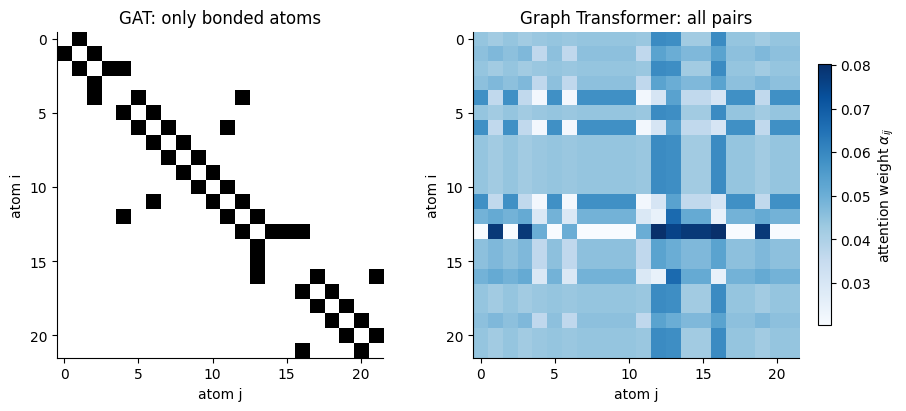

In [6]:
# @title Plot: who talks to whom?
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, M, title, cmap in [(axes[0], A, "GAT: only bonded atoms", "Greys"),
                           (axes[1], weights, "Graph Transformer: all pairs", "Blues")]:
    im = ax.imshow(M, cmap=cmap)
    ax.set(title=title, xlabel="atom j", ylabel="atom i",
           xticks=range(0, mol.num_nodes, 5), yticks=range(0, mol.num_nodes, 5))
    ax.grid(False)
fig.colorbar(im, ax=axes[1], shrink=0.8, label=r"attention weight $\alpha_{ij}$")
plt.show()

### The problem: attention ignores the bonds

Look at the formula again: the **bonds do not appear anywhere**. Attention over all atoms only sees a *list of atoms*. Two carbons, one in a ring and one at the end of a chain, start with the same vector and get **exactly the same result**. (You can see this as stripes in the plot above.)

Let's count how many different results we get:

In [7]:
def count_different(x):
    return torch.unique(x.float().round(decimals=4), dim=0).size(0)

print(f"{mol.num_nodes} atoms, {count_different(mol.x)} atom types -> {count_different(out)} different results")

22 atoms, 5 atom types -> 5 different results


Only one result per atom type: attention cannot tell two carbons apart. We need to tell it **where each atom is**.

## 4. Positional encodings: where is each atom?

In a sentence, a word's position is simply 1, 2, 3, ... A graph has no first or last node, so instead we describe **what the surroundings of each node look like**.

A simple way: put a **random walker** on atom $i$. At each step it moves to a random neighbor. We record the chance that it is **back at atom $i$** after 1, 2, ..., 16 steps:

$$\text{pe}_i = [\,p_i(1),\; p_i(2),\; \dots,\; p_i(16)\,]$$

This is the **random-walk positional encoding (RWPE)**. Atoms in different places get different lists.

**Example.** Take three carbons of our molecule, **A**, **B** and **C**. For attention they are all just "C". Their position tags are not:

In [8]:
CARBONS = {"A": 0, "B": 2, "C": 5}                     # name -> atom index in the molecule
STEPS = [2, 4, 6, 8]                                   # a few of the 16 steps (odd steps are ~0 here)

for name, i in CARBONS.items():
    chances = "  ".join(f"{mol.pe[i, k - 1]:.2f}" for k in STEPS)
    print(f"carbon {name}: chance to be back after 2, 4, 6, 8 steps = {chances}")

carbon A: chance to be back after 2, 4, 6, 8 steps = 0.50  0.33  0.26  0.22
carbon B: chance to be back after 2, 4, 6, 8 steps = 0.61  0.49  0.42  0.38
carbon C: chance to be back after 2, 4, 6, 8 steps = 0.33  0.19  0.14  0.11


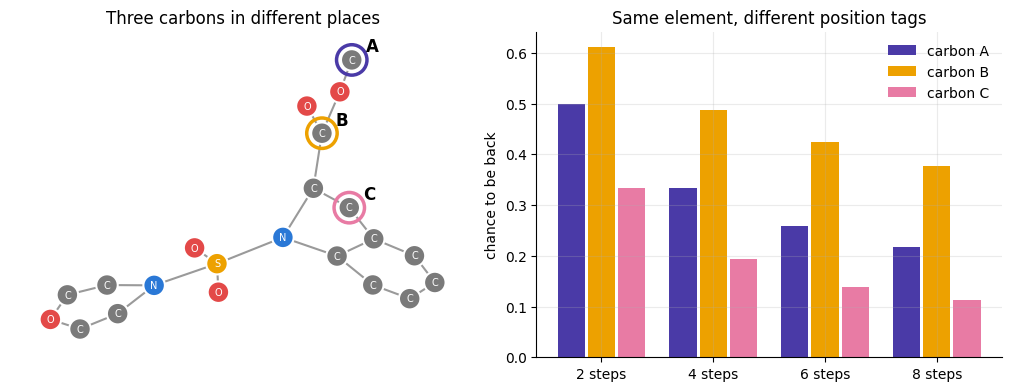

In [9]:
# @title Plot: position tags of carbons A, B and C
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
draw_mol(axes[0], mol, pos)
for name, i in CARBONS.items():
    axes[0].scatter(*pos[i], s=480, facecolors="none", edgecolors=CARBON_COLORS[name], linewidths=2.5)
    axes[0].annotate(name, pos[i], xytext=(10, 6), textcoords="offset points", fontsize=12, fontweight="bold")
axes[0].set_title("Three carbons in different places")

width = 0.27
for n, (name, i) in enumerate(CARBONS.items()):
    x = np.arange(len(STEPS)) + (n - 1) * width
    axes[1].bar(x, [mol.pe[i, k - 1] for k in STEPS], width * 0.9, color=CARBON_COLORS[name], label=f"carbon {name}")
axes[1].set(xticks=range(len(STEPS)), xticklabels=[f"{k} steps" for k in STEPS],
            ylabel="chance to be back", title="Same element, different position tags")
axes[1].legend(frameon=False)
plt.show()

* **A** is at the end of a chain. It has only one neighbor, so the walker often comes straight back.
* **B** is next to a dead end (the O drawn next to it), which sends the walker back to B even more often.
* **C** is inside a ring, where the walker can wander off in two directions, so it comes back less often.

Now we **add** the position tag to each atom's vector and run the same attention again:

In [10]:
torch.manual_seed(SEED)
pe_lin = nn.Linear(PE_DIM, d)                          # position tag -> vector of size d

with torch.no_grad():
    h_with_pe = atom_emb(mol.x.view(-1)) + pe_lin(mol.pe)
    out_pe, _ = self_attention(h_with_pe)

print(f"without position tags: {count_different(out)} different results")
print(f"with position tags:    {count_different(out_pe)} different results (out of {mol.num_nodes} atoms)")

without position tags: 5 different results
with position tags:    19 different results (out of 22 atoms)


Now atoms of the same element in different places get different results. (A few atoms are true mirror images of each other in the molecule, so they still share one.)

## 5. GAT vs. Graph Transformer

We build **one** layer and use it for both models. This follows **GPS** (Rampášek et al., 2022), a popular Graph Transformer:

* **Local part** (a GAT layer that also reads the bond type): each atom attends to its **bonded neighbors**.
* **Global part** (only in the Graph Transformer): each atom attends to **every atom of the same molecule**.
* The results are **added** to the old vector.

| Model | Local attention (neighbors) | Global attention (all atoms) | Position tags |
|---|:-:|:-:|:-:|
| **GAT** | ✓ | | |
| **Graph Transformer** | ✓ | ✓ | ✓ |

So the only difference between the two models is exactly what makes a Graph Transformer: **global attention + position tags**.

One technical detail: molecules have different sizes. `to_dense_batch` pads them to the same size, and `key_padding_mask` makes sure no atom pays attention to the padding.

In [11]:
class GraphLayer(nn.Module):
    def __init__(self, dim, use_global):
        super().__init__()
        self.local_attn = GATConv(dim, dim // 4, heads=4, edge_dim=dim)   # 4 heads x dim/4 = dim
        self.global_attn = nn.MultiheadAttention(dim, num_heads=4, batch_first=True) if use_global else None
        self.norm = nn.BatchNorm1d(dim)

    def forward(self, h, edge_index, edge_attr, batch):
        out = h + self.local_attn(h, edge_index, edge_attr)   # talk to bonded neighbors
        if self.global_attn is not None:                      # talk to every atom of the same molecule
            h_pad, mask = to_dense_batch(h, batch)            # [molecules, max_atoms, dim]
            a, self.weights = self.global_attn(h_pad, h_pad, h_pad, key_padding_mask=~mask)
            out = out + a[mask]                               # back to [atoms, dim]
        return F.relu(self.norm(out))


class GraphNet(nn.Module):
    def __init__(self, use_global, dim=64, num_layers=4):
        super().__init__()
        self.use_pe = use_global                       # the Graph Transformer also gets position tags
        self.atom_emb = nn.Embedding(28, dim)          # atom type -> vector
        self.bond_emb = nn.Embedding(4, dim)           # bond type -> vector
        self.pe_lin = nn.Linear(PE_DIM, dim)           # position tag -> vector
        self.layers = nn.ModuleList([GraphLayer(dim, use_global) for _ in range(num_layers)])
        self.out = nn.Linear(dim, 1)

    def forward(self, data):
        h = self.atom_emb(data.x.view(-1))
        if self.use_pe:
            h = h + self.pe_lin(data.pe)               # add the position tag
        e = self.bond_emb(data.edge_attr)
        for layer in self.layers:
            h = layer(h, data.edge_index, e, data.batch)
        return self.out(global_add_pool(h, data.batch)).view(-1)   # one number per molecule

Both models are trained in the same way. We keep the test MAE from the epoch with the best validation MAE.

In [12]:
MODELS = {"GAT": dict(use_global=False), "Graph Transformer": dict(use_global=True)}
EPOCHS = 60

def train_one_epoch(model, opt):
    model.train()
    for data in train_loader:
        data = data.to(DEVICE)
        loss = F.l1_loss(model(data), data.y)
        opt.zero_grad()
        loss.backward()
        opt.step()

@torch.no_grad()
def evaluate(model, loader):                           # mean absolute error
    model.eval()
    errors = [(model(data.to(DEVICE)) - data.y).abs() for data in loader]
    return torch.cat(errors).mean().item()

def train(config):
    torch.manual_seed(SEED)
    model = GraphNet(**config).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    best_val, val_curve = float("inf"), []
    for _ in range(EPOCHS):
        train_one_epoch(model, opt)
        val_curve.append(evaluate(model, val_loader))
        if val_curve[-1] < best_val:
            best_val, test_mae = val_curve[-1], evaluate(model, test_loader)
    return model, val_curve, test_mae

In [13]:
results = {}
for name, config in MODELS.items():
    model, val_curve, test_mae = train(config)
    results[name] = dict(model=model, val=val_curve, test=test_mae)
    print(f"{name:17s} test MAE {test_mae:.3f}")

GAT               test MAE 0.443


Graph Transformer test MAE 0.274


## 6. Results

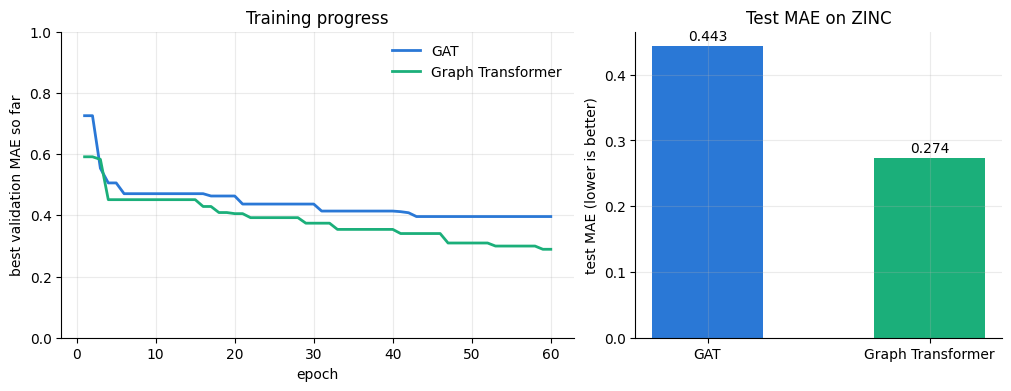

In [14]:
# @title Plot: training progress and test MAE
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True, gridspec_kw={"width_ratios": [1.4, 1]})
for name, r in results.items():
    axes[0].plot(range(1, EPOCHS + 1), np.minimum.accumulate(r["val"]), lw=2, color=MODEL_COLORS[name], label=name)
axes[0].set(xlabel="epoch", ylabel="best validation MAE so far", title="Training progress", ylim=(0, 1))
axes[0].legend(frameon=False)

names = list(results)
bars = axes[1].bar(names, [results[n]["test"] for n in names], width=0.5,
                   color=[MODEL_COLORS[n] for n in names])
axes[1].bar_label(bars, fmt="%.3f", padding=2)
axes[1].set(ylabel="test MAE (lower is better)", title="Test MAE on ZINC")
plt.show()

* The **Graph Transformer** reaches a clearly lower error than **GAT**.
* Both models share the same local GAT layer, so the gain comes from **global attention + position tags**: every atom can directly use information from the whole molecule (for example rings on the other side), which matters for the solubility score.

## 7. What does attention look at?

GAT only looks at bonded neighbors (distance 1). Does the **global attention** of the trained Graph Transformer also look at atoms far away? We take its last layer and:

* **left**: pick one atom (black ring) and color every atom by how much attention it gets from it,
* **right**: average the attention over all test molecules, grouped by **how many bonds apart** the two atoms are.

In [15]:
@torch.no_grad()
def attention_of(model, m):
    model.eval()
    model(m.to(DEVICE))
    return model.layers[-1].weights[0].cpu()           # [n, n] global attention of the last layer

def bonds_apart(m):                                    # number of bonds between every pair of atoms
    length = dict(nx.all_pairs_shortest_path_length(to_networkx(m, to_undirected=True)))
    return torch.tensor([[length[i][j] for j in range(m.num_nodes)] for i in range(m.num_nodes)])

gt_model = results["Graph Transformer"]["model"]
MAX_DIST = 8
dist = torch.cat([bonds_apart(m).flatten() for m in test_ds]).clamp(max=MAX_DIST)
attn = torch.cat([attention_of(gt_model, m).flatten() for m in test_ds])
mean_attn = [attn[dist == k].mean().item() for k in range(MAX_DIST + 1)]
uniform = np.mean([1 / m.num_nodes for m in test_ds])  # if every atom got the same attention

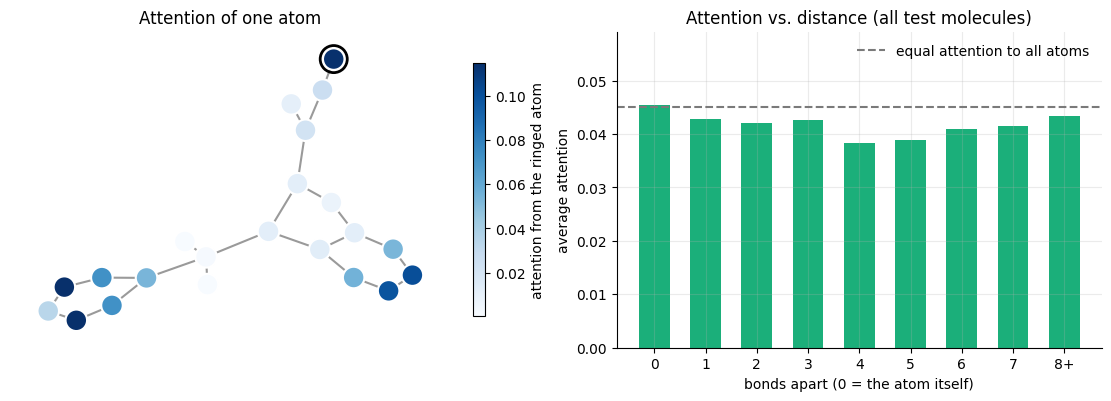

In [16]:
# @title Plot: global attention of the trained Graph Transformer
query = 0
att = attention_of(gt_model, mol)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), constrained_layout=True, gridspec_kw={"width_ratios": [1, 1.1]})
nodes = draw_mol(axes[0], mol, pos, node_color=att[query].tolist(), cmap="Blues", labels=False, highlight=query)
fig.colorbar(nodes, ax=axes[0], shrink=0.8, label="attention from the ringed atom")
axes[0].set_title("Attention of one atom")

labels = [str(k) for k in range(MAX_DIST)] + [f"{MAX_DIST}+"]
axes[1].bar(labels, mean_attn, width=0.6, color=MODEL_COLORS["Graph Transformer"])
axes[1].axhline(uniform, color="#7a7a7a", ls="--", lw=1.5, label="equal attention to all atoms")
axes[1].set(xlabel="bonds apart (0 = the atom itself)", ylabel="average attention",
            title="Attention vs. distance (all test molecules)", ylim=(0, 1.3 * max(mean_attn + [uniform])))
axes[1].legend(frameon=False, loc="upper right")
plt.show()

* In this run, the ringed atom pays the most attention to the **rings at the other end** of the molecule, not to its bonded neighbor. A single GAT layer could never do that.
* On average, attention is spread almost **evenly over near and far atoms**: atoms 8 or more bonds apart get about as much as direct neighbors. A 4-layer GAT cannot see further than 4 bonds at all.

## 8. Takeaways

* **Attention** lets every node talk to every other node in **one** layer. GAT uses attention too, but only over neighbors, one hop per layer.
* Attention over all nodes **ignores the edges**: it sees the graph as a list of nodes.
* **Positional encodings** (here: random-walk return chances) tell each node where it is. They turn a Transformer into a *Graph* Transformer.
* A **Graph Transformer** (GPS style) = local attention over neighbors + global attention over all nodes + position tags.
* Cost: global attention compares **every pair** of nodes. That is fine for molecules (~23 atoms) but too slow for graphs with millions of nodes.